### В этом коде:
1. мы сначала визуализируем траекторию для заполнения мета-атомами
2. затем отмечаем точками будущие центры мета-атомов
3. считаем фазовое смещение в этих точках
4. загружаем обученную модель, заполняем ячейками точки 

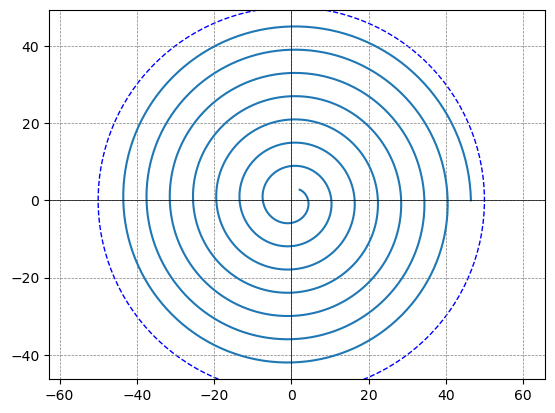

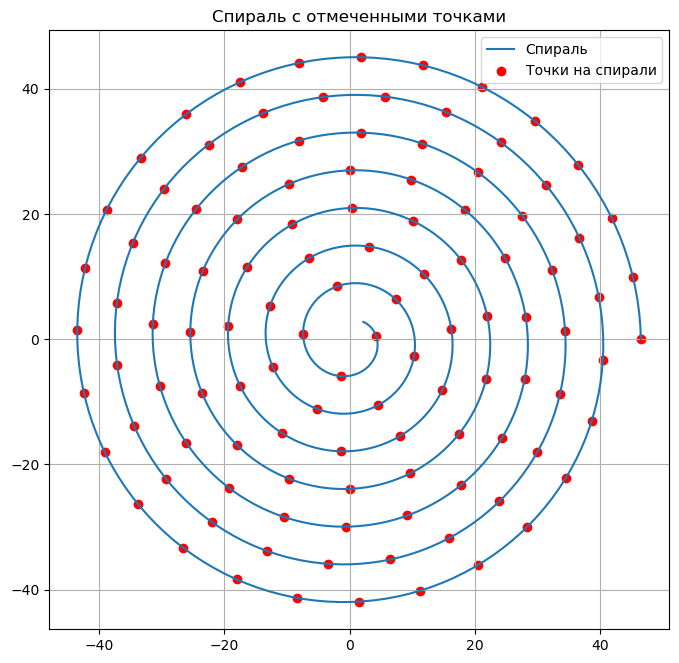

Координаты точек на спирали:
[[ 4.65000000e+01  0.00000000e+00]
 [ 4.52153215e+01  9.89771489e+00]
 [ 4.18427774e+01  1.92898314e+01]
 [ 3.65296107e+01  2.77363372e+01]
 [ 2.95165865e+01  3.48348836e+01]
 [ 2.11290383e+01  4.02410360e+01]
 [ 1.17634069e+01  4.36864862e+01]
 [ 1.86972637e+00  4.49941897e+01]
 [-8.06913841e+00  4.40889878e+01]
 [-1.75602470e+01  4.10041532e+01]
 [-2.61279760e+01  3.58870265e+01]
 [-3.33364145e+01  2.89857489e+01]
 [-3.88086128e+01  2.06408254e+01]
 [-4.22561690e+01  1.12769605e+01]
 [-4.34908512e+01  1.37613774e+00]
 [-4.24379368e+01 -8.54486238e+00]
 [-3.91428237e+01 -1.79611009e+01]
 [-3.37712683e+01 -2.63674351e+01]
 [-2.66030793e+01 -3.33062293e+01]
 [-1.80149209e+01 -3.83833417e+01]
 [-8.47742536e+00 -4.13078856e+01]
 [ 1.47910838e+00 -4.19158979e+01]
 [ 1.12997714e+01 -4.01629058e+01]
 [ 2.04154068e+01 -3.61110433e+01]
 [ 2.83055774e+01 -3.00089934e+01]
 [ 3.45016783e+01 -2.21923777e+01]
 [ 3.86195800e+01 -1.31079110e+01]
 [ 4.04218150e+01 -3.29793

In [4]:
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
import numpy as np
import conf

dB = 5 + 2 # side of square of single cell. So It depends on library. Let's count size + 2 microns
APPERTURE_DIAMETER = 100 # # 100 microns in diameters
N_AMOUNT_SPIRAL = APPERTURE_DIAMETER/dB # this quantity for whole diameter
RESOLUTION_SPIRAL = 1000
OFFSET_SPIRAL = dB/2
STEP = 10  # Шаг между точками
focal_length = 100  # Фокусное расстояние
wavelength = conf.inc_lcen  # Длина волны 3 microns

def calculate_phase_shift(diameter, offset, step, focal_length, wavelength):
    radius = diameter / 2
    
    # Проверка, что отступ корректен
    if offset >= radius:
        raise ValueError("Отступ X должен быть меньше радиуса круга.")
    
    # Генерируем углы для спирали
    theta = np.linspace(0, N_AMOUNT_SPIRAL * np.pi, RESOLUTION_SPIRAL)  # Увеличьте количество оборотов и точек при необходимости. 
    
    # Генерируем радиусы для спирали, от (radius - offset) до offset
    r = np.linspace(radius - offset, offset, len(theta))
    
    # Преобразуем из полярных координат в декартовы
    x = r * np.cos(theta)
    y = r * np.sin(theta)

    # Выбираем точки с заданным шагом вдоль спирали
    distances = np.sqrt(np.diff(x)**2 + np.diff(y)**2)
    cumulative_distances = np.insert(np.cumsum(distances), 0, 0)
    # Общая длина пути
    total_length = cumulative_distances[-1]
    
    # Равномерное разбиение длины пути с заданным шагом
    sampled_distances = np.arange(0, total_length, step)
    
    # Интерполяция координат x и y вдоль длины пути
    interp_x = interp1d(cumulative_distances, x, kind='linear')
    interp_y = interp1d(cumulative_distances, y, kind='linear')

    # Получаем координаты точек
    sampled_points = np.column_stack((interp_x(sampled_distances), interp_y(sampled_distances)))

    # Расчет фазового смещения
    phase_shifts = []
    for point in sampled_points:
        d = np.linalg.norm(point)  # расстояние до фокуса (в данном случае (0, 0))
        delta_phi = (2 * np.pi / wavelength) * (d - focal_length) % (2 * np.pi) # Нормировка к диапазону [0, 2π]
        normalized_phi = delta_phi - (2 * np.pi) if delta_phi > 0 else delta_phi # Принудительная нормировка к диапазону [2π, 0]
        phase_shifts.append(normalized_phi)
    
    # Визуализация
    # Создаем фигуру
    fig, ax = plt.subplots()
    ax.plot(x, y, label='Спираль')
    
    # Рисуем круг
    circle = plt.Circle((0, 0), radius, color='blue', fill=False, linestyle='--', label='Круг')
    ax.add_artist(circle)
    # Настройка осей
    ax.set_aspect('equal', adjustable='datalim')
    plt.axhline(0, color='black', linewidth=0.5)
    plt.axvline(0, color='black', linewidth=0.5)
    plt.grid(color='gray', linestyle='--', linewidth=0.5)
    
    plt.figure(figsize=(8, 8))
    plt.plot(x, y, label="Спираль")
    plt.scatter(sampled_points[:, 0], sampled_points[:, 1], color='red', label="Точки на спирали")
    plt.gca().set_aspect('equal', adjustable='box')
    plt.legend()
    plt.grid()
    plt.title("Спираль с отмеченными точками")
    plt.show()
    
    return sampled_points, phase_shifts

# Пример использования
points, phases = calculate_phase_shift(APPERTURE_DIAMETER, OFFSET_SPIRAL, STEP, focal_length, wavelength)

# Вывод результатов
print("Координаты точек на спирали:")
print(points)
print("\nФазовые смещения в этих точках:")
print(phases)


### SOLVED
    Текущий код строит центры на началах коорднинат отрезков спирали. Эти отрезки имеют не постоянную длину. Нам такое не подходит, так как нужен стабильный шаг.
    Надо доработать код ниже чтобы реализовать равный шаг между центрами по всей длине.   
    

#### Следующий шаг - нужно в этих точках расставить ячейки
1. Берем значение фазового сдвига - пропускаем через модель - получаем коэффиценты формы
2. Правильно заполняем ячейками по спирали сохраняя нормальность к спирали.
3. Дальше что-нибудь оптимизируем...

**Заметка** Главное не забыть пересчитать библиотеку под этот тип заполнения, потому что с таких расположением атомов расчеты подготовленной библиотеки не верны.

Для текущей библиотеки заполнение атомов должно быть в матричной форме, чтобы волна проходила в другном направлении

In [10]:
type(phases[1])

numpy.float64

In [13]:
#save numpy with data into new file "points" and "phases"
#сохранить в бинарном формате .npy
np.save('points.npy', points)
np.save('phases.npy', phases)
print("Данные успешно сохранены!")

Данные успешно сохранены!


In [14]:
#Let's load a model
import torch
from torch import nn

loaded_model = torch.load("model_shape_prediction.pth")
X_new_data = torch.tensor([-3.0])
X_new_data = X_new_data.to(torch.float32)  # Приводим к типу float32 (если нужно)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
X_new_data = X_new_data.to(device)
loaded_model = loaded_model.to(device)

# Устанавливаем режим оценки
loaded_model.eval()

# Прогнозирование
with torch.no_grad():
    prediction = loaded_model(X_new_data)
    
# Вывод
print("Выходные данные модели:", prediction)

/tmp/ipykernel_4773/1892152829.py:5: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  loaded_model = torch.load("model_shape_prediction.pth")


Выходные данные модели: tensor([1.7086, 2.2814], device='cuda:0')


In [15]:
type(prediction)

torch.Tensor